(sec-2)=
# 2. Análisis exploratorio de datos orientado a decisiones

En esta sección se amplía el EDA del Entregable 1, que no se descarta: se repiten sus hallazgos centrales con el código de este entregable y se agregan los análisis que pide el enunciado y que el Entregable 1 no tenía, como la estimación del ruido de etiquetas, el cambio de distribución con pruebas formales, los atípicos multivariados, la asociación de los identificadores con la etiqueta y el AUC univariado de cada atributo. Cada análisis cierra con la decisión de preprocesamiento, el impacto en la arquitectura y en la validación, y los riesgos, y cada hallazgo se registra en la tabla de trazabilidad de la sección {ref}`2.3 <sec-2-3>`. Desde la sección {ref}`2.2 <sec-2-2>`, todo se calcula solo con el conjunto de entrenamiento.

(sec-2-1)=
## 2.1 EDA general

(sec-2-1-1)=
### 2.1.1 Variable objetivo

Se cuantifica el desbalance con la razón entre la clase mayoritaria y la minoritaria, y con la entropía de la distribución, $H = -\sum_c p_c \log_2 p_c$, que se normaliza por su máximo, $\log_2 K$.

Clase,Original,Sin repetidas,Entrenamiento,Validación,Prueba
Blackhole,"21,37","22,91","23,67","22,07","21,15"
Flooding,"16,15","10,33","10,33","10,35","10,34"
Normal,"21,42","22,97","22,79","23,46","23,15"
Sybil,"19,71","20,89","20,59","21,65","21,27"
Wormhole,"21,35","22,89","22,62","22,47","24,09"
Entropía normalizada,"1,00","0,98","0,98","0,98","0,98"
Razón mayor / menor,"1,33","2,22","2,29","2,27","2,33"


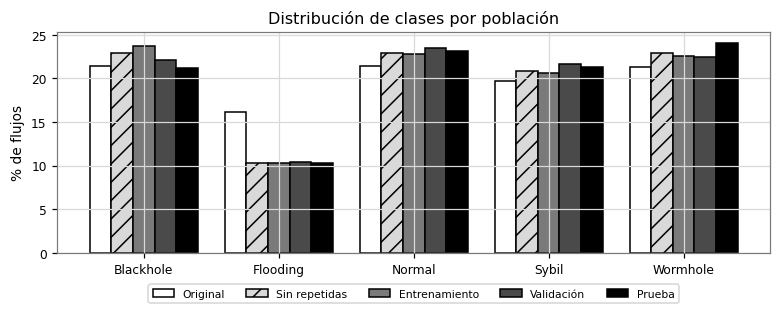

**Interpretación.** En entrenamiento, la clase más frecuente es Blackhole (23,7 %) y la menos frecuente Flooding (10,3 %), una razón de 2,29 a 1, con una entropía normalizada de 0,978, muy cerca del máximo de 1. Al retirar las filas repetidas, Flooding baja de 16,1 % a 10,3 %, porque concentra la mayoría de las repeticiones, y la partición conserva las proporciones con diferencias de pocas décimas.

Esto significa que el desbalance es moderado: no hay clases raras, pero tampoco una distribución uniforme, y una exactitud global podría ocultar un mal desempeño en Flooding.

Por tal motivo, se mantiene la entropía cruzada ponderada con $w_c = n / (K n_c)$, sin remuestreo ni *focal loss*, que se reservan para desbalances más fuertes, y se reportan métricas robustas al desbalance: F1 macro, *balanced accuracy* y AUC-PR macro.

**Decisión de preprocesamiento.** Pesos de clase calculados solo con entrenamiento; sin remuestreo.

**Impacto en la arquitectura y la validación.** Todas las arquitecturas usan la misma pérdida ponderada, y la partición se estratifica por clase.

**Riesgos.** Remuestrear antes de partir filtraría copias de una misma serie a la prueba; por eso no se aplica.

In [7]:
import matplotlib.pyplot as plt
from scipy import stats

def resumen_clases(indices):
    p = np.bincount(y[indices], minlength=K) / len(indices)
    return p, float(-(p * np.log2(p)).sum() / np.log2(K)), float(p.max() / p.min())

POBLACION = {"Original": np.arange(len(datos)), "Sin repetidas": indices_unicos, "Entrenamiento": ID_ENT, "Validación": ID_VAL, "Prueba": ID_PRU}
tabla_clases = pd.DataFrame({n: 100 * resumen_clases(i)[0] for n, i in POBLACION.items()}, index=CLASES)
tabla_clases.loc["Entropía normalizada"] = [resumen_clases(i)[1] for i in POBLACION.values()]
tabla_clases.loc["Razón mayor / menor"] = [resumen_clases(i)[2] for i in POBLACION.values()]
tabla(tabla_clases.reset_index(names="Clase"), {c: "{:.2f}" for c in POBLACION})
fig, eje = plt.subplots(figsize=(7.2, 3.0))
ancho = 0.16
for j, (nombre, indices) in enumerate(POBLACION.items()):
    eje.bar(np.arange(K) + (j - 2) * ancho, 100 * resumen_clases(indices)[0], ancho, color=["white", GRIS_CLARO, GRIS_MEDIO, GRIS_OSCURO, NEGRO][j], edgecolor=NEGRO, label=nombre,
            hatch=["", "//", "", "", ""][j])
eje.set_xticks(range(K), CLASES)
eje.set_ylabel("% de flujos")
eje.set_title("Distribución de clases por población")
eje.legend(ncol=5, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()
p_ent, h_ent, razon_ent = resumen_clases(ID_ENT)
interpretar(f'''**Interpretación.** En entrenamiento, la clase más frecuente es {CLASES[p_ent.argmax()]} ({pct(p_ent.max())}) y la menos frecuente {CLASES[p_ent.argmin()]} ({pct(p_ent.min())}), una razón de {num(razon_ent, 2)} a 1, con una entropía normalizada de {num(h_ent, 3)}, muy cerca del máximo de 1. Al retirar las filas repetidas, Flooding baja de {num(tabla_clases.loc["Flooding", "Original"], 1)} % a {num(tabla_clases.loc["Flooding", "Sin repetidas"], 1)} %, porque concentra la mayoría de las repeticiones, y la partición conserva las proporciones con diferencias de pocas décimas.

Esto significa que el desbalance es moderado: no hay clases raras, pero tampoco una distribución uniforme, y una exactitud global podría ocultar un mal desempeño en Flooding.

Por tal motivo, se mantiene la entropía cruzada ponderada con $w_c = n / (K n_c)$, sin remuestreo ni *focal loss*, que se reservan para desbalances más fuertes, y se reportan métricas robustas al desbalance: F1 macro, *balanced accuracy* y AUC-PR macro.

**Decisión de preprocesamiento.** Pesos de clase calculados solo con entrenamiento; sin remuestreo.

**Impacto en la arquitectura y la validación.** Todas las arquitecturas usan la misma pérdida ponderada, y la partición se estratifica por clase.

**Riesgos.** Remuestrear antes de partir filtraría copias de una misma serie a la prueba; por eso no se aplica.''')

(sec-2-1-2)=
### 2.1.2 Calidad del dataset

El contrato de datos ya descartó valores faltantes, corruptos e inconsistentes (sección {ref}`1.5 <sec-1-5>`). Aquí se cuantifican los duplicados exactos, los casi duplicados y el ruido de etiquetas, que fija el techo de desempeño de la sección 6.5. Los casi duplicados se definen como en el Entregable 1: flujos cuyo logaritmo coincide en todos los atributos al redondear a dos decimales, una diferencia de cerca de 1 %. El ruido de etiquetas se estima por dos vías: los grupos de flujos idénticos o casi idénticos con etiquetas distintas, y el aprendizaje confiado (*confident learning*; Northcutt et al., 2021), que compara la etiqueta de cada flujo de entrenamiento con las probabilidades fuera de pliegue de un LightGBM, con pliegues agrupados por bloque para no premiar la memorización de la serie.

In [8]:
from sklearn.model_selection import StratifiedGroupKFold

repetidas_atributos = datos[ATRIBUTOS].duplicated(keep=False)
conflictos_exactos = datos.loc[repetidas_atributos].groupby(ATRIBUTOS, dropna=False)["label"].nunique()
grupos_conflicto = int((conflictos_exactos > 1).sum())
filas_conflicto = int(datos.loc[repetidas_atributos].groupby(ATRIBUTOS)["label"].transform("nunique").gt(1).sum())
def clave_filas(M, decimales=2):
    # Clave binaria de cada fila redondeada: dos flujos son casi duplicados si comparten la clave
    M = np.ascontiguousarray(np.round(M, decimales) + 0.0)
    return pd.factorize(M.view(np.dtype((np.void, M.dtype.itemsize * M.shape[1]))).ravel())[0]
casi = pd.DataFrame({"clave": clave_filas(x_log[indices_unicos]), "y": y[indices_unicos]})
tam_grupo = casi.groupby("clave")["y"].transform("size")
clases_grupo = casi.groupby("clave")["y"].transform("nunique")
frac_casi = float((tam_grupo > 1).mean())
frac_casi_conflicto = float((clases_grupo > 1).mean())

RUTA_CL = ANALISIS / "aprendizaje_confiado.npz"
if RUTA_CL.exists():
    cl = np.load(RUTA_CL)
    oof = cl["oof"]
else:
    import lightgbm as lgb
    X_ent = H["X"][ID_ENT]
    oof = np.zeros((len(ID_ENT), K))
    for f_ent, f_val in StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X_ent, y[ID_ENT], bloques[ID_ENT]):
        m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=63, class_weight="balanced", random_state=42, n_jobs=2, verbose=-1)
        m.fit(X_ent[f_ent], y[ID_ENT][f_ent])
        oof[f_val] = m.predict_proba(X_ent[f_val])
    np.savez(RUTA_CL, oof=oof)
y_ent = y[ID_ENT]
umbral = np.array([oof[y_ent == c, c].mean() for c in range(K)])
confiables = oof >= umbral
candidata = np.where(confiables.any(1), np.argmax(np.where(confiables, oof, -1), 1), -1)
C_CL = np.zeros((K, K), int)
for c in range(K):
    for j in range(K):
        C_CL[c, j] = int(((y_ent == c) & (candidata == j)).sum())
ruido_cl = float(C_CL[~np.eye(K, dtype=bool)].sum() / C_CL.sum())
matriz_cl = pd.DataFrame(C_CL, index=[f"Etiqueta {c}" for c in CLASES], columns=[f"Probable {c}" for c in CLASES])
tabla(matriz_cl.reset_index(names="Conteo conjunto"))
calidad = pd.DataFrame({"Indicador": ["Filas repetidas en atributos y etiqueta", "Grupos de atributos idénticos con etiquetas distintas", "Filas en esos grupos",
                                      "Flujos sin repetir con un casi duplicado", "Flujos en grupos casi duplicados con clases distintas", "Ruido estimado por aprendizaje confiado (entrenamiento)"],
                        "Valor": [f"{int(repetidas.sum()):,}".replace(",", " "), f"{grupos_conflicto:,}".replace(",", " "), f"{filas_conflicto:,}".replace(",", " "), pct(frac_casi), pct(frac_casi_conflicto), pct(ruido_cl)]})
tabla(calidad)
par_bw = (C_CL[0, 4] + C_CL[4, 0]) / max(C_CL[~np.eye(K, dtype=bool)].sum(), 1)
texto_conflicto = "ningún grupo de flujos con atributos idénticos tiene etiquetas distintas" if grupos_conflicto == 0 else f"{grupos_conflicto} grupos de atributos idénticos tienen etiquetas distintas y reúnen {filas_conflicto} filas"
par_sf = (C_CL[3, 1] + C_CL[1, 3]) / max(C_CL[~np.eye(K, dtype=bool)].sum(), 1)
interpretar(f'''**Interpretación.** El archivo tiene {num(int(repetidas.sum()), 0)} filas repetidas, que se retiran antes de partir, y {texto_conflicto}. Tras retirar las repetidas, el {pct(frac_casi)} de los flujos tiene un casi duplicado y el {pct(frac_casi_conflicto)} cae en un grupo casi duplicado con más de una clase. El aprendizaje confiado estima que el {pct(ruido_cl)} de las etiquetas de entrenamiento serían de otra clase, el par Blackhole–Wormhole reúne el {pct(par_bw)} de esos casos y el par Sybil–Flooding, el {pct(par_sf)}.

Hay que tener en cuenta que el aprendizaje confiado no distingue el ruido de etiqueta de la superposición real entre clases: un flujo de Blackhole que se comporta como uno de Wormhole aparece como sospechoso aunque su etiqueta sea correcta. Es decir, la cifra es una cota superior de la parte del error que ningún modelo podría eliminar, y se concentra en el mismo par de ataques que el Entregable 1 señaló como el más confundido.

Por lo anterior, conviene usar esta estimación como una de las cotas del techo de desempeño de la sección 6.5, junto con la del vecino más cercano, y no corregir etiquetas, porque no hay una muestra auditada que permita separar el ruido de la superposición.

**Decisión de preprocesamiento.** Se retiran las filas repetidas, como en el Entregable 1; las etiquetas no se modifican.

**Impacto en la arquitectura y la validación.** El margen de mejora real depende del techo; si el mejor modelo se acerca a él, no se justifica una arquitectura más compleja (sección 12.1 del enunciado).

**Riesgos.** Los casi duplicados entre particiones inflan el desempeño; su proporción entre entrenamiento y prueba se audita en la sección 2.1.4 y su efecto en el desempeño, en la sección 6.''')

Conteo conjunto,Probable Blackhole,Probable Flooding,Probable Normal,Probable Sybil,Probable Wormhole
Etiqueta Blackhole,14 499,8,9,0,1 273
Etiqueta Flooding,5,7 121,0,96,117
Etiqueta Normal,12,282,15 961,0,160
Etiqueta Sybil,0,1 426,46,12 693,64
Etiqueta Wormhole,1 337,61,185,2,12 086


Indicador,Valor
Filas repetidas en atributos y etiqueta,8 219
Grupos de atributos idénticos con etiquetas distintas,0
Filas en esos grupos,0
Flujos sin repetir con un casi duplicado,"19,6 %"
Flujos en grupos casi duplicados con clases distintas,"0,5 %"
Ruido estimado por aprendizaje confiado (entrenamiento),"7,5 %"


**Interpretación.** El archivo tiene 8 219 filas repetidas, que se retiran antes de partir, y ningún grupo de flujos con atributos idénticos tiene etiquetas distintas. Tras retirar las repetidas, el 19,6 % de los flujos tiene un casi duplicado y el 0,5 % cae en un grupo casi duplicado con más de una clase. El aprendizaje confiado estima que el 7,5 % de las etiquetas de entrenamiento serían de otra clase, el par Blackhole–Wormhole reúne el 51,3 % de esos casos y el par Sybil–Flooding, el 29,9 %.

Hay que tener en cuenta que el aprendizaje confiado no distingue el ruido de etiqueta de la superposición real entre clases: un flujo de Blackhole que se comporta como uno de Wormhole aparece como sospechoso aunque su etiqueta sea correcta. Es decir, la cifra es una cota superior de la parte del error que ningún modelo podría eliminar, y se concentra en el mismo par de ataques que el Entregable 1 señaló como el más confundido.

Por lo anterior, conviene usar esta estimación como una de las cotas del techo de desempeño de la sección 6.5, junto con la del vecino más cercano, y no corregir etiquetas, porque no hay una muestra auditada que permita separar el ruido de la superposición.

**Decisión de preprocesamiento.** Se retiran las filas repetidas, como en el Entregable 1; las etiquetas no se modifican.

**Impacto en la arquitectura y la validación.** El margen de mejora real depende del techo; si el mejor modelo se acerca a él, no se justifica una arquitectura más compleja (sección 12.1 del enunciado).

**Riesgos.** Los casi duplicados entre particiones inflan el desempeño; su proporción entre entrenamiento y prueba se audita en la sección {ref}`2.1.4 <sec-2-1-4>` y su efecto en el desempeño, en la sección 6.

(sec-2-1-3)=
### 2.1.3 Sesgos y atajos

Se revisan los sesgos de representación, de adquisición y de orden, y se mide si algún atributo irrelevante predice la etiqueta por sí solo (*shortcut learning*; Geirhos et al., 2020). Para los identificadores categóricos se usa la V de Cramér frente a la etiqueta, $V = \sqrt{\chi^2 / (n (\min(r, c) - 1))}$, y para el orden del archivo, la proporción de flujos consecutivos que comparten clase.

In [9]:
def cramer(a, b):
    t = pd.crosstab(a, b).to_numpy()
    return float(np.sqrt(stats.chi2_contingency(t)[0] / (t.sum() * (min(t.shape) - 1))))

etiqueta = pd.Series(y[indices_unicos])
sub = datos.iloc[indices_unicos]
asociacion = pd.DataFrame({"Identificador": ["SrcPort", "DstPort", "SrcAddr", "DstAddr"],
                           "Valores distintos": [sub[c].nunique() for c in ["SrcPort", "DstPort", "SrcAddr", "DstAddr"]],
                           "V de Cramér con la etiqueta": [cramer(sub[c].to_numpy(), etiqueta.to_numpy()) for c in ["SrcPort", "DstPort", "SrcAddr", "DstAddr"]]})
tabla(asociacion, {"V de Cramér con la etiqueta": "{:.3f}"})
tabla(pd.crosstab(sub["label"].str.replace(" Attack", "").str.replace(" Traffic", ""), sub["SrcPort"]).reset_index(names="Clase"))
orden = y[np.sort(indices_unicos)]
mismos = float((orden[1:] == orden[:-1]).mean())
esperado = float((np.bincount(orden) / len(orden)) @ (np.bincount(orden) / len(orden)))
direcciones_multiclase = int((sub.groupby("SrcAddr")["label"].nunique() > 1).sum())
interpretar(f'''**Interpretación.** Los puertos y las direcciones IP se asocian fuertemente con la clase: la V de Cramér va de {num(asociacion["V de Cramér con la etiqueta"].min(), 3)} a {num(asociacion["V de Cramér con la etiqueta"].max(), 3)}, y el puerto 654 no aparece en Flooding ni en Sybil. En el orden del archivo, el {pct(mismos)} de los flujos consecutivos comparte clase, frente al {pct(esperado)} que se esperaría si el orden fuera aleatorio, y {direcciones_multiclase} de las {sub["SrcAddr"].nunique()} direcciones de origen aparecen en dos o más clases.

Esto significa que los identificadores describen cómo se armaron las simulaciones y no el comportamiento del tráfico: el puerto 654 corresponde al tráfico de control de AODV y su presencia depende del escenario, y el archivo está ordenado por clase, de modo que `FlowID` delata la etiqueta. Se trata de sesgos de adquisición y de orden, no de representación, porque las cinco clases tienen un tamaño parecido.

Por esta razón, lo indicado es mantener fuera de las entradas los seis identificadores, como en el Entregable 1, y comprobar en la sección 6 que el desempeño de los modelos no cambie entre los flujos con y sin el puerto 654, que es el diagnóstico de atajos de la sección 12.3 del enunciado.

**Decisión de preprocesamiento.** Se excluyen `FlowID`, `SrcAddr`, `SrcPort`, `DstAddr`, `DstPort` y `Protocol`.

**Impacto en la arquitectura y la validación.** Las arquitecturas que necesitan un grafo entre nodos, como las GNN de la literatura, quedan fuera del Top 10, porque lo arman con estas direcciones (sección 3.2).

**Riesgos.** Los atributos de tráfico también pueden reflejar el escenario y no solo el ataque; ese riesgo se mide con la validación adversarial de la sección 2.1.5.''')

Identificador,Valores distintos,V de Cramér con la etiqueta
SrcPort,2,"0,631"
DstPort,2,"0,631"
SrcAddr,176,"0,614"
DstAddr,218,"0,229"


Clase,9,654
Blackhole,11 248,14 862
Flooding,11 776,0
Normal,11 294,14 878
Sybil,23 808,0
Wormhole,25 494,592


**Interpretación.** Los puertos y las direcciones IP se asocian fuertemente con la clase: la V de Cramér va de 0,229 a 0,631, y el puerto 654 no aparece en Flooding ni en Sybil. En el orden del archivo, el 92,5 % de los flujos consecutivos comparte clase, frente al 21,2 % que se esperaría si el orden fuera aleatorio, y 125 de las 176 direcciones de origen aparecen en dos o más clases.

Esto significa que los identificadores describen cómo se armaron las simulaciones y no el comportamiento del tráfico: el puerto 654 corresponde al tráfico de control de AODV y su presencia depende del escenario, y el archivo está ordenado por clase, de modo que `FlowID` delata la etiqueta. Se trata de sesgos de adquisición y de orden, no de representación, porque las cinco clases tienen un tamaño parecido.

Por esta razón, lo indicado es mantener fuera de las entradas los seis identificadores, como en el Entregable 1, y comprobar en la sección 6 que el desempeño de los modelos no cambie entre los flujos con y sin el puerto 654, que es el diagnóstico de atajos de la sección 12.3 del enunciado.

**Decisión de preprocesamiento.** Se excluyen `FlowID`, `SrcAddr`, `SrcPort`, `DstAddr`, `DstPort` y `Protocol`.

**Impacto en la arquitectura y la validación.** Las arquitecturas que necesitan un grafo entre nodos, como las GNN de la literatura, quedan fuera del Top 10, porque lo arman con estas direcciones (sección {ref}`3.2 <sec-3-2>`).

**Riesgos.** Los atributos de tráfico también pueden reflejar el escenario y no solo el ataque; ese riesgo se mide con la validación adversarial de la sección {ref}`2.1.5 <sec-2-1-5>`.

(sec-2-1-4)=
### 2.1.4 Partición del dataset y auditoría de fuga

La partición se hereda del Entregable 1 sin cambios: estratificada por clase y agrupada por bloques de 1000 flujos, con semilla 42, y la prueba quedó sellada con su suma SHA-256 antes de entrenar cualquier modelo. Aquí se ejecutan las verificaciones de la sección 10.1 del enunciado que dependen solo de los datos; la de transformaciones se prueba con datos sintéticos, y la de etiquetas permutadas, en la sección 6.

In [10]:
B_ENT, B_VAL, B_PRU = (set(bloques[i]) for i in (ID_ENT, ID_VAL, ID_PRU))
def huella(indices, con_etiqueta=False):
    m = np.round(datos[ATRIBUTOS].to_numpy()[indices], 8)
    filas = [hashlib.sha1(f.tobytes() + (bytes([e]) if con_etiqueta else b"")).hexdigest() for f, e in zip(m, y[indices])]
    return set(filas)
H_ENT, H_VAL, H_PRU = huella(ID_ENT), huella(ID_VAL), huella(ID_PRU)
claves = clave_filas(x_log)
c_ent = np.unique(claves[ID_ENT])
casi_val, casi_pru = float(np.isin(claves[ID_VAL], c_ent).mean()), float(np.isin(claves[ID_PRU], c_ent).mean())
np.save(ANALISIS / "prueba_con_casi_duplicado.npy", np.isin(claves[ID_PRU], c_ent))

# Fuga por transformaciones: con datos sintéticos, cambiar validación y prueba no debe mover los estadísticos de la estandarización
sintetico = np.random.default_rng(0).lognormal(size=(len(datos), len(ATRIBUTOS)))
X_a, _ = D.preparar_pliegue(ID_ENT, np.log1p(sintetico))
alterado = sintetico.copy()
alterado[np.concatenate([ID_VAL, ID_PRU])] *= 1000
X_b, _ = D.preparar_pliegue(ID_ENT, np.log1p(alterado))
transformacion_ok = bool(np.allclose(X_a[ID_ENT], X_b[ID_ENT]))

AUDITORIA = pd.DataFrame({
    "Verificación": ["Intersección de unidades de independencia (bloques)", "Duplicados exactos entre particiones", "Casi duplicados de prueba con vecino en entrenamiento",
                     "Fuga temporal", "Fuga espacial", "Fuga por transformaciones", "Fuga por atributos", "Validación adversarial", "Fuga por modelos preentrenados", "Sanidad con etiquetas permutadas"],
    "Cómo se ejecuta": ["Intersección de los bloques de cada partición", "Huella SHA-1 de cada fila de atributos y búsqueda de colisiones", "Clave de log(1 + x) redondeado a 2 decimales",
                        "No aplica: no hay marca de tiempo ni rezagos como entrada", "No aplica: no hay coordenadas", "Prueba con datos sintéticos: se alteran validación y prueba y se comparan los estadísticos",
                        "AUC univariado de cada atributo e identificador (sección 2.2.5)", "Clasificador que separa entrenamiento de prueba (sección 2.1.5)",
                        "No aplica: ningún modelo usa pesos preentrenados", "Entrenamiento con etiquetas permutadas (sección 6.3)"],
    "Resultado": [f"Entrenamiento ∩ prueba: {len(B_ENT & B_PRU)}; entrenamiento ∩ validación: {len(B_ENT & B_VAL)}; validación ∩ prueba: {len(B_VAL & B_PRU)}",
                  f"Entrenamiento ∩ prueba: {len(H_ENT & H_PRU)}; entrenamiento ∩ validación: {len(H_ENT & H_VAL)}; validación ∩ prueba: {len(H_VAL & H_PRU)}",
                  f"Prueba: {pct(casi_pru)}; validación: {pct(casi_val)}", "No aplica", "No aplica", "Aprobada" if transformacion_ok else "Fallida", "Ver sección 2.2.5", "Ver sección 2.1.5", "No aplica", "Ver sección 6.3"],
    "Criterio de aprobación": ["Intersección vacía", "Cero colisiones", "Menos de 5 %, tolerancia declarada a priori, y desempeño con y sin esos casos en la sección 6", "Orden estricto", "Distancia mayor que el *buffer*",
                               "Estadísticos idénticos", "Ningún atributo sospechoso sin justificación", "AUC no distinguible de 0,5 o diferencia explicada", "Riesgo declarado", "Score cercano al azar"]})
tabla(AUDITORIA)
AUDITORIA.to_csv(RESULTADOS / "auditoria_fuga.csv", index=False, encoding="utf-8-sig")
assert not (B_ENT & B_PRU) and not (B_ENT & B_VAL) and not (B_VAL & B_PRU) and transformacion_ok
interpretar(f'''**Interpretación.** Las particiones no comparten ningún bloque, y entre entrenamiento y prueba hay {len(H_ENT & H_PRU)} filas idénticas en sus atributos; la prueba con datos sintéticos confirma que la estandarización solo usa entrenamiento. El {pct(casi_pru)} de los flujos de prueba tiene un casi duplicado en entrenamiento, por debajo de la tolerancia de 5 %, y en validación la cifra es de {pct(casi_val)}.

Es decir, las verificaciones de la sección 10.1 que dependen de los datos se aprueban. Hay que tener en cuenta que un casi duplicado entre bloques distintos es posible, porque un mismo escenario largo puede aportar bloques a varias particiones; por eso la sección 6 compara el desempeño con y sin esos flujos.

En consecuencia, se decide conservar la partición heredada sin cambios, con la regla de oro del enunciado: si una verificación fallara, el benchmark no sería válido hasta corregir la causa.

**Decisión de preprocesamiento.** La estandarización y los pesos de clase se ajustan solo con entrenamiento, también dentro de cada pliegue de la validación cruzada.

**Impacto en la arquitectura y la validación.** Todos los modelos usan la misma partición y la prueba se evalúa una sola vez por corrida.

**Riesgos.** El bloque aproxima la simulación de origen, pero no la identifica; la fuga entre bloques vecinos no se elimina por completo.''')

Verificación,Cómo se ejecuta,Resultado,Criterio de aprobación
Intersección de unidades de independencia (bloques),Intersección de los bloques de cada partición,Entrenamiento ∩ prueba: 0; entrenamiento ∩ validación: 0; validación ∩ prueba: 0,Intersección vacía
Duplicados exactos entre particiones,Huella SHA-1 de cada fila de atributos y búsqueda de colisiones,Entrenamiento ∩ prueba: 0; entrenamiento ∩ validación: 0; validación ∩ prueba: 0,Cero colisiones
Casi duplicados de prueba con vecino en entrenamiento,Clave de log(1 + x) redondeado a 2 decimales,"Prueba: 1,8 %; validación: 1,8 %","Menos de 5 %, tolerancia declarada a priori, y desempeño con y sin esos casos en la sección 6"
Fuga temporal,No aplica: no hay marca de tiempo ni rezagos como entrada,No aplica,Orden estricto
Fuga espacial,No aplica: no hay coordenadas,No aplica,Distancia mayor que el *buffer*
Fuga por transformaciones,Prueba con datos sintéticos: se alteran validación y prueba y se comparan los estadísticos,Aprobada,Estadísticos idénticos
Fuga por atributos,AUC univariado de cada atributo e identificador (sección 2.2.5),Ver sección 2.2.5,Ningún atributo sospechoso sin justificación
Validación adversarial,Clasificador que separa entrenamiento de prueba (sección 2.1.5),Ver sección 2.1.5,"AUC no distinguible de 0,5 o diferencia explicada"
Fuga por modelos preentrenados,No aplica: ningún modelo usa pesos preentrenados,No aplica,Riesgo declarado
Sanidad con etiquetas permutadas,Entrenamiento con etiquetas permutadas (sección 6.3),Ver sección 6.3,Score cercano al azar


**Interpretación.** Las particiones no comparten ningún bloque, y entre entrenamiento y prueba hay 0 filas idénticas en sus atributos; la prueba con datos sintéticos confirma que la estandarización solo usa entrenamiento. El 1,8 % de los flujos de prueba tiene un casi duplicado en entrenamiento, por debajo de la tolerancia de 5 %, y en validación la cifra es de 1,8 %.

Es decir, las verificaciones de la sección 10.1 que dependen de los datos se aprueban. Hay que tener en cuenta que un casi duplicado entre bloques distintos es posible, porque un mismo escenario largo puede aportar bloques a varias particiones; por eso la sección 6 compara el desempeño con y sin esos flujos.

En consecuencia, se decide conservar la partición heredada sin cambios, con la regla de oro del enunciado: si una verificación fallara, el benchmark no sería válido hasta corregir la causa.

**Decisión de preprocesamiento.** La estandarización y los pesos de clase se ajustan solo con entrenamiento, también dentro de cada pliegue de la validación cruzada.

**Impacto en la arquitectura y la validación.** Todos los modelos usan la misma partición y la prueba se evalúa una sola vez por corrida.

**Riesgos.** El bloque aproxima la simulación de origen, pero no la identifica; la fuga entre bloques vecinos no se elimina por completo.

(sec-2-1-5)=
### 2.1.5 Cambio de distribución

Se comparan las distribuciones de entrenamiento, validación y prueba con tres pruebas complementarias: Kolmogorov-Smirnov por atributo, con corrección de Holm; la discrepancia media máxima (MMD) con núcleo gaussiano, que compara las distribuciones conjuntas, con su valor p por permutación (Gretton et al., 2012), y un clasificador adversarial que intenta distinguir las particiones, cuyo AUC sería 0,5 si no hubiera desplazamiento (Lopez-Paz y Oquab, 2017). Con decenas de miles de flujos, cualquier diferencia es significativa, de modo que la lectura se apoya en el tamaño del efecto: el estadístico D de Kolmogorov-Smirnov, la MMD y el AUC.

In [11]:
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score

ks = []
for j, a in enumerate(ATRIBUTOS):
    for nombre, otra in (("validación", ID_VAL), ("prueba", ID_PRU)):
        r = stats.ks_2samp(x_log[ID_ENT, j], x_log[otra, j])
        ks.append({"Atributo": a, "Comparación": f"entrenamiento frente a {nombre}", "D": r.statistic, "p": r.pvalue})
ks = pd.DataFrame(ks)
ks["p Holm"] = multipletests(ks["p"], method="holm")[1]
tabla_ks = ks.pivot(index="Atributo", columns="Comparación", values="D").reset_index()
tabla(tabla_ks, {c: "{:.3f}" for c in tabla_ks.columns if c != "Atributo"})

def mmd_rbf(A, B, permutaciones=200, semilla=0):
    rng = np.random.default_rng(semilla)
    Z = np.vstack([A, B])
    cuadrados = (Z ** 2).sum(1)
    d2 = np.maximum(cuadrados[:, None] + cuadrados[None, :] - 2 * Z @ Z.T, 0)
    gamma = 1 / np.median(d2[d2 > 0])
    Kz = np.exp(-gamma * d2)
    n = len(A)
    def estadistico(ix):
        a, b = ix[:n], ix[n:]
        return Kz[np.ix_(a, a)].mean() + Kz[np.ix_(b, b)].mean() - 2 * Kz[np.ix_(a, b)].mean()
    base = estadistico(np.arange(len(Z)))
    nulos = np.array([estadistico(rng.permutation(len(Z))) for _ in range(permutaciones)])
    return base, (1 + (nulos >= base).sum()) / (permutaciones + 1)

RUTA_SHIFT = ANALISIS / "cambio_distribucion.json"
if RUTA_SHIFT.exists():
    shift = json.loads(RUTA_SHIFT.read_text())
else:
    import lightgbm as lgb
    rng = np.random.default_rng(0)
    shift = {}
    for nombre, otra in (("validación", ID_VAL), ("prueba", ID_PRU)):
        a, b = rng.choice(ID_ENT, 1000, replace=False), rng.choice(otra, 1000, replace=False)
        shift[f"mmd_{nombre}"], shift[f"p_mmd_{nombre}"] = mmd_rbf(H["X"][a], H["X"][b])
        # Validación adversarial con pliegues agrupados por bloque y prueba de permutación sobre el AUC
        filas = np.concatenate([ID_ENT, otra])
        etiqueta_adv = np.r_[np.zeros(len(ID_ENT)), np.ones(len(otra))]
        def auc_adversarial(etq, semilla=0):
            prob = np.zeros(len(filas))
            for f_e, f_v in StratifiedGroupKFold(5, shuffle=True, random_state=semilla).split(filas, etq, bloques[filas]):
                m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, random_state=0, n_jobs=2, verbose=-1).fit(H["X"][filas[f_e]], etq[f_e])
                prob[f_v] = m.predict_proba(H["X"][filas[f_v]])[:, 1]
            return roc_auc_score(etq, prob)
        shift[f"auc_{nombre}"] = auc_adversarial(etiqueta_adv)
        # Permutación por bloques: se reasigna la partición a bloques completos, que es la unidad de independencia
        b_unicos = np.unique(bloques[filas])
        nulos = []
        for i in range(20):
            elegidos = set(np.random.default_rng(i).choice(b_unicos, len(set(bloques[otra])), replace=False))
            nulos.append(auc_adversarial(np.isin(bloques[filas], list(elegidos)).astype(float)))
        shift[f"auc_nulo_{nombre}"] = nulos
    RUTA_SHIFT.write_text(json.dumps(shift, indent=1, default=float))
resumen_shift = pd.DataFrame({"Comparación": ["Entrenamiento frente a validación", "Entrenamiento frente a prueba"],
                              "D máximo de KS": [ks.loc[ks["Comparación"].str.contains(n), "D"].max() for n in ("validación", "prueba")],
                              "Atributos con p Holm < 0,05": [int((ks.loc[ks["Comparación"].str.contains(n), "p Holm"] < ALFA).sum()) for n in ("validación", "prueba")],
                              "MMD": [shift["mmd_validación"], shift["mmd_prueba"]], "p de MMD": [shift["p_mmd_validación"], shift["p_mmd_prueba"]],
                              "AUC adversarial": [shift["auc_validación"], shift["auc_prueba"]],
                              "AUC nulo, máximo de 20 asignaciones por bloques": [max(shift["auc_nulo_validación"]), max(shift["auc_nulo_prueba"])],
                              "p de permutación por bloques": [(1 + sum(v >= shift[f"auc_{n}"] for v in shift[f"auc_nulo_{n}"])) / 21 for n in ("validación", "prueba")]})
tabla(resumen_shift, {"D máximo de KS": "{:.3f}", "MMD": "{:.4f}", "p de MMD": "{:.4f}", "AUC adversarial": "{:.3f}", "AUC nulo, máximo de 20 asignaciones por bloques": "{:.3f}", "p de permutación por bloques": "{:.3f}"})
peor = ks.sort_values("D", ascending=False).iloc[0]
p_adv = {n: (1 + sum(v >= shift[f"auc_{n}"] for v in shift[f"auc_nulo_{n}"])) / 21 for n in ("validación", "prueba")}
interpretar(f'''**Interpretación.** Con pliegues agrupados por bloque, el clasificador adversarial separa el entrenamiento de la validación con un AUC de {num(shift["auc_validación"], 3)} y de la prueba con {num(shift["auc_prueba"], 3)}, valores que caen dentro de la distribución nula que se obtiene al asignar bloques al azar, cuyo máximo es de {num(max(shift["auc_nulo_validación"]), 3)} y {num(max(shift["auc_nulo_prueba"]), 3)}, con valores p de permutación de {num(p_adv["validación"], 3)} y {num(p_adv["prueba"], 3)}. En cambio, las pruebas fila a fila sí detectan diferencias: los 16 atributos rechazan la igualdad de Kolmogorov-Smirnov tras Holm, con D de hasta {num(peor["D"], 3)} en `{peor["Atributo"]}`, y la MMD tiene p = {num(shift["p_mmd_prueba"], 3)}, aunque con tamaños de efecto pequeños.

Esto corrige una lectura del Entregable 1, que reportó un AUC adversarial de 0,889 y 0,848 con una validación cruzada sin agrupar: ese clasificador reconocía la serie de cada flujo, porque los flujos de un mismo bloque caían a la vez en sus pliegues de entrenamiento y de evaluación, y no medía un desplazamiento entre particiones. Es decir, las particiones difieren entre sí lo mismo que dos conjuntos cualesquiera de series, y las pruebas fila a fila rechazan porque tratan como independientes flujos que no lo son (sección 2.2.3).

Por ello, se recomienda no aplicar adaptación de dominio y evaluar el benchmark con intervalos por *bootstrap* de bloques y por bloque de prueba, que sí respetan la dependencia, porque el desempeño absoluto depende de qué series caigan en la prueba, como mostró el intervalo por bloques del Entregable 1.

**Decisión de preprocesamiento.** Ninguna adicional; la estandarización ya se ajusta solo en entrenamiento.

**Impacto en la arquitectura y la validación.** Se prefieren los intervalos por bloques y las pruebas pareadas sobre semillas, que comparan los modelos sobre las mismas series.

**Riesgos.** La brecha entre validación y prueba que observó el Entregable 1 no se explica por un desplazamiento propio de la partición, sino por la variación entre series; se prueba en la tabla B (sección 7).''')

Atributo,entrenamiento frente a prueba,entrenamiento frente a validación
AverageHopCount,"0,101","0,065"
FlowDuration/s,"0,064","0,098"
LostPackets,"0,074","0,051"
MeanDelay/s,"0,051","0,096"
MeanJitter/s,"0,051","0,107"
MeanPacketSize,"0,047","0,079"
PacketDropRate,"0,047","0,045"
RxByteRate/s,"0,085","0,047"
RxBytes,"0,060","0,061"
RxPacketRate/s,"0,104","0,048"


Comparación,D máximo de KS,"Atributos con p Holm < 0,05",MMD,p de MMD,AUC adversarial,"AUC nulo, máximo de 20 asignaciones por bloques",p de permutación por bloques
Entrenamiento frente a validación,"0,107",16,"0,0063","0,0050","0,515","0,622","0,381"
Entrenamiento frente a prueba,"0,128",16,"0,0071","0,0050","0,451","0,596","0,714"


**Interpretación.** Con pliegues agrupados por bloque, el clasificador adversarial separa el entrenamiento de la validación con un AUC de 0,515 y de la prueba con 0,451, valores que caen dentro de la distribución nula que se obtiene al asignar bloques al azar, cuyo máximo es de 0,622 y 0,596, con valores p de permutación de 0,381 y 0,714. En cambio, las pruebas fila a fila sí detectan diferencias: los 16 atributos rechazan la igualdad de Kolmogorov-Smirnov tras Holm, con D de hasta 0,128 en `TxPacketRate/s`, y la MMD tiene p = 0,005, aunque con tamaños de efecto pequeños.

Esto corrige una lectura del Entregable 1, que reportó un AUC adversarial de 0,889 y 0,848 con una validación cruzada sin agrupar: ese clasificador reconocía la serie de cada flujo, porque los flujos de un mismo bloque caían a la vez en sus pliegues de entrenamiento y de evaluación, y no medía un desplazamiento entre particiones. Es decir, las particiones difieren entre sí lo mismo que dos conjuntos cualesquiera de series, y las pruebas fila a fila rechazan porque tratan como independientes flujos que no lo son (sección {ref}`2.2.3 <sec-2-2-3>`).

Por ello, se recomienda no aplicar adaptación de dominio y evaluar el benchmark con intervalos por *bootstrap* de bloques y por bloque de prueba, que sí respetan la dependencia, porque el desempeño absoluto depende de qué series caigan en la prueba, como mostró el intervalo por bloques del Entregable 1.

**Decisión de preprocesamiento.** Ninguna adicional; la estandarización ya se ajusta solo en entrenamiento.

**Impacto en la arquitectura y la validación.** Se prefieren los intervalos por bloques y las pruebas pareadas sobre semillas, que comparan los modelos sobre las mismas series.

**Riesgos.** La brecha entre validación y prueba que observó el Entregable 1 no se explica por un desplazamiento propio de la partición, sino por la variación entre series; se prueba en la tabla B (sección 7).

(sec-2-2)=
## 2.2 EDA específico: datos tabulares

Desde aquí se trabaja solo con entrenamiento. Se aplica el bloque de datos tabulares del enunciado: tipos de variables, distribuciones y escalas, valores faltantes, relaciones entre variables, detección de fuga por atributo, estructura de grupos e implicaciones para la familia de modelos.

(sec-2-2-1)=
### 2.2.1 Tipos de variables, distribuciones y escalas

Para cada atributo se registra su tipo, su asimetría y su curtosis antes y después de $\log(1 + x)$, y su proporción de atípicos univariados por el criterio de 1,5 veces el rango intercuartílico. Los atípicos multivariados se miden con la distancia de Mahalanobis robusta, con la covarianza de determinante mínimo (Rousseeuw y Van Driessen, 1999), y el umbral del percentil 99,9 de una χ² con 16 grados de libertad.

In [12]:
from sklearn.covariance import MinCovDet

crudo_ent = datos[ATRIBUTOS].to_numpy(float)[ID_ENT]
log_ent = x_log[ID_ENT]
def atipicos(v):
    q1, q3 = np.percentile(v, [25, 75])
    return float(((v < q1 - 1.5 * (q3 - q1)) | (v > q3 + 1.5 * (q3 - q1))).mean())
distribuciones = pd.DataFrame({"Atributo": ATRIBUTOS, "Tipo": ["discreto" if np.allclose(crudo_ent[:, j], np.round(crudo_ent[:, j])) else "continuo" for j in range(len(ATRIBUTOS))],
                               "Valores distintos": [len(np.unique(crudo_ent[:, j])) for j in range(len(ATRIBUTOS))],
                               "Asimetría original": stats.skew(crudo_ent), "Asimetría con log": stats.skew(log_ent),
                               "Curtosis original": stats.kurtosis(crudo_ent), "Curtosis con log": stats.kurtosis(log_ent),
                               "% atípicos con log": [100 * atipicos(log_ent[:, j]) for j in range(len(ATRIBUTOS))]})
tabla(distribuciones, {c: "{:.2f}" for c in distribuciones.columns[3:]} | {"Valores distintos": "{:,.0f}"})
muestra_mcd = np.random.default_rng(0).choice(len(ID_ENT), 20000, replace=False)
mcd = MinCovDet(random_state=0).fit(H["X"][ID_ENT][muestra_mcd])
dist = mcd.mahalanobis(H["X"][ID_ENT])
corte = stats.chi2.ppf(0.999, len(ATRIBUTOS))
atipico_multi = dist > corte
por_clase = pd.Series(atipico_multi).groupby(y[ID_ENT]).mean().rename(lambda c: CLASES[c])
tabla(pd.DataFrame({"Clase": por_clase.index, "% atípicos multivariados": 100 * por_clase.to_numpy()}), {"% atípicos multivariados": "{:.1f}"})
mas_asimetrico = distribuciones.loc[distribuciones["Asimetría original"].abs().idxmax()]
interpretar(f'''**Interpretación.** Los {len(ATRIBUTOS)} atributos son numéricos, {int((distribuciones["Tipo"] == "discreto").sum())} de ellos discretos (conteos y tamaños), y en escala original son muy asimétricos: el caso extremo es `{mas_asimetrico["Atributo"]}`, con asimetría de {num(mas_asimetrico["Asimetría original"], 1)} y curtosis de {num(mas_asimetrico["Curtosis original"], 0)}. Con $\\log(1 + x)$, la mediana del valor absoluto de la asimetría baja de {num(distribuciones["Asimetría original"].abs().median(), 2)} a {num(distribuciones["Asimetría con log"].abs().median(), 2)}. Sin embargo, el {pct(atipico_multi.mean())} de los flujos de entrenamiento supera el umbral de Mahalanobis robusto, y la proporción va de {pct(por_clase.min())} en {por_clase.idxmin()} a {pct(por_clase.max())} en {por_clase.idxmax()}.

Lo anterior indica que los atípicos multivariados no son errores de medición, sino comportamiento propio de algunas clases: un ataque altera la combinación de atributos, y eliminarlos quitaría justamente la señal que se quiere detectar.

Por tal motivo, se mantiene la transformación logarítmica con estandarización del Entregable 1, sin eliminar atípicos ni usar un escalado robusto, y la robustez ante valores extremos se evalúa con perturbaciones controladas en la sección 6.

**Decisión de preprocesamiento.** $\\log(1 + x)$, recorte de `PacketDropRate` en 1 y estandarización con entrenamiento.

**Impacto en la arquitectura y la validación.** Las arquitecturas con funciones de base acotadas, como la KAN, recortan la entrada en [−5, 5]; la proporción de valores fuera de ese rango se reporta en la sección 4.2.

**Riesgos.** Un modelo puede apoyarse en la rareza de un flujo y no en su clase; el análisis de errores de la sección 6.6 revisa los casos de frontera.

**Valores faltantes.** El contrato de datos no encontró faltantes, de modo que no hay mecanismo MCAR, MAR o MNAR que modelar ni imputación que ajustar. La robustez ante atributos faltantes, que sí ocurre en un despliegue con fallas de sensores (Di et al., 2026), se evalúa como perturbación en la sección 6.''')

Atributo,Tipo,Valores distintos,Asimetría original,Asimetría con log,Curtosis original,Curtosis con log,% atípicos con log
FlowDuration/s,continuo,42 145,"1,86","-0,74","11,83","0,44","1,09"
TxPackets,discreto,2 050,"61,42","0,44","5337,11","-0,71","0,04"
RxPackets,discreto,2 605,"12,18","0,56","285,22","-0,67","0,08"
LostPackets,discreto,641,"104,36","0,22","12029,88","-0,68","0,03"
TxBytes,discreto,8 030,"41,20","0,49","2953,56","-0,61","0,19"
RxBytes,discreto,5 762,"9,98","0,51","144,45","-0,63","0,20"
TxPacketRate/s,continuo,51 405,"162,26","2,65","29079,14","15,05","2,11"
RxPacketRate/s,continuo,55 333,"145,83","2,72","22492,07","16,59","1,48"
TxByteRate/s,continuo,51 464,"163,37","0,47","29366,83","-0,60","0,08"
RxByteRate/s,continuo,56 521,"145,91","0,65","22509,09","-0,84","0,03"


Clase,% atípicos multivariados
Blackhole,"82,2"
Flooding,"61,6"
Normal,"42,7"
Sybil,"12,0"
Wormhole,"75,2"


**Interpretación.** Los 16 atributos son numéricos, 6 de ellos discretos (conteos y tamaños), y en escala original son muy asimétricos: el caso extremo es `TxByteRate/s`, con asimetría de 163,4 y curtosis de 29 367. Con $\log(1 + x)$, la mediana del valor absoluto de la asimetría baja de 29,42 a 0,69. Sin embargo, el 55,0 % de los flujos de entrenamiento supera el umbral de Mahalanobis robusto, y la proporción va de 12,0 % en Sybil a 82,2 % en Blackhole.

Lo anterior indica que los atípicos multivariados no son errores de medición, sino comportamiento propio de algunas clases: un ataque altera la combinación de atributos, y eliminarlos quitaría justamente la señal que se quiere detectar.

Por tal motivo, se mantiene la transformación logarítmica con estandarización del Entregable 1, sin eliminar atípicos ni usar un escalado robusto, y la robustez ante valores extremos se evalúa con perturbaciones controladas en la sección 6.

**Decisión de preprocesamiento.** $\log(1 + x)$, recorte de `PacketDropRate` en 1 y estandarización con entrenamiento.

**Impacto en la arquitectura y la validación.** Las arquitecturas con funciones de base acotadas, como la KAN, recortan la entrada en [−5, 5]; la proporción de valores fuera de ese rango se reporta en la sección {ref}`4.2 <sec-4-2>`.

**Riesgos.** Un modelo puede apoyarse en la rareza de un flujo y no en su clase; el análisis de errores de la sección 6.6 revisa los casos de frontera.

**Valores faltantes.** El contrato de datos no encontró faltantes, de modo que no hay mecanismo MCAR, MAR o MNAR que modelar ni imputación que ajustar. La robustez ante atributos faltantes, que sí ocurre en un despliegue con fallas de sensores (Di et al., 2026), se evalúa como perturbación en la sección 6.

(sec-2-2-2)=
### 2.2.2 Relaciones entre variables y detección de fuga por atributo

Se miden la correlación de Pearson y de Spearman entre atributos, la información mutua de cada atributo con la clase, la multicolinealidad con el factor de inflación de varianza, $VIF_j = 1 / (1 - R_j^2)$, y el AUC univariado de cada atributo frente a la etiqueta, en esquema uno contra todos y promediado entre clases. Un AUC univariado cercano a 1 indicaría una variable posterior al evento o derivada de la etiqueta.

Variable,Información mutua (nats),VIF,AUC univariado
TxByteRate/s,"0,975","449,6","0,785"
TxPacketRate/s,"0,924","24,8","0,784"
RxByteRate/s,"0,845","367,7","0,778"
Throughput/Kbps,"0,845","192,0","0,778"
RxPacketRate/s,"0,817","289,8","0,775"
PacketDropRate,"0,814","9,4","0,731"
TxBytes,"0,848","2209,3","0,720"
RxBytes,"0,723","616,6","0,708"
TxPackets,"0,637","2156,6","0,707"
RxPackets,"0,518","516,9","0,700"


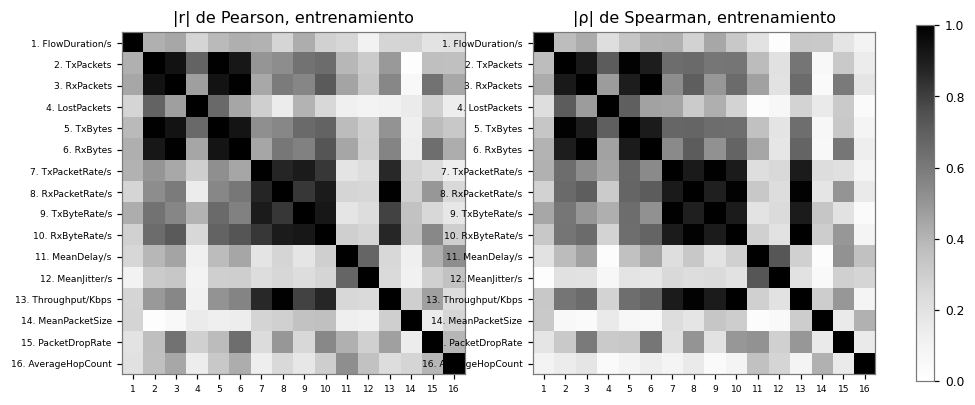

**Interpretación.** El atributo con mayor AUC univariado es `TxByteRate/s`, con 0,785, y ningún atributo de tráfico supera 0,95, el umbral a partir del cual una variable sería sospechosa de fuga. `FlowID` obtiene 0,741, menos que varios atributos de tráfico, porque su relación con la clase no es monótona: el archivo está ordenado en tramos de una sola clase, y el AUC solo mide un orden. Sin embargo, el Entregable 1 mostró que `FlowID` por sí solo, en un modelo no lineal, alcanza un F1 macro de 0,926 con partición aleatoria y de 0,859 con la agrupada, de modo que sí es una fuga. En multicolinealidad, el VIF llega a 2 209 y el número de condición de la matriz de correlación es de 190; el par más correlacionado es `RxPackets` y `RxBytes`, con $|r|$ = 0,9940.

Esto se explica por la construcción de los atributos: las tasas son cocientes de los conteos sobre la duración y `Throughput/Kbps` es `RxByteRate/s` en otras unidades, como confirmó el contrato de datos. Es decir, la dimensión efectiva es menor que 16, pero ningún atributo de tráfico funciona por sí solo como una fuga, mientras que los identificadores sí, aunque el AUC univariado no lo capte en `FlowID`.

Por lo anterior, conviene conservar los 16 atributos, como hace la literatura, porque las redes con regularización toleran la colinealidad, y mantener fuera los identificadores. Para los modelos que leen el vector como secuencia, la correlación alta entre atributos vecinos (por ejemplo, conteos de paquetes y de bytes) da contenido a la convolución local, pero ese contenido depende de un orden de columnas que no tiene significado físico; la RQ3 lo pone a prueba.

**Decisión de preprocesamiento.** Sin selección de atributos por colinealidad.

**Impacto en la arquitectura y la validación.** La redundancia favorece la regularización y no justifica capas muy anchas; el espacio de la búsqueda de arquitectura incluye anchos de 16 a 256 para medirlo.

**Riesgos.** Seleccionar atributos con todo el conjunto filtraría información de la prueba; si se hiciera, tendría que ir dentro de cada pliegue.

In [13]:
from sklearn.feature_selection import mutual_info_classif

pearson = np.corrcoef(log_ent, rowvar=False)
spearman = stats.spearmanr(log_ent).statistic
vif = np.diag(np.linalg.pinv(pearson))
autovalores = np.linalg.eigvalsh(pearson)
condicion = float(np.sqrt(autovalores.max() / max(autovalores.min(), 1e-12)))
muestra_mi = np.random.default_rng(0).permutation(len(ID_ENT))[:30000]
info_mutua = mutual_info_classif(log_ent[muestra_mi], y_ent[muestra_mi], random_state=0)
def auc_univariado(v, etq):
    return float(np.mean([max(roc_auc_score(etq == c, v), 1 - roc_auc_score(etq == c, v)) for c in range(K)]))
y_sin = y[indices_unicos]
identificadores_num = {"FlowID": datos["FlowID"].to_numpy(float), "SrcPort": datos["SrcPort"].to_numpy(float), "DstPort": datos["DstPort"].to_numpy(float),
                       "SrcAddr (último octeto)": datos["SrcAddr"].str.split(".").str[-1].astype(float).to_numpy(), "DstAddr (último octeto)": datos["DstAddr"].str.split(".").str[-1].astype(float).to_numpy()}
relacion = pd.DataFrame({"Variable": ATRIBUTOS, "Información mutua (nats)": info_mutua, "VIF": vif, "AUC univariado": [auc_univariado(log_ent[:, j], y_ent) for j in range(len(ATRIBUTOS))]})
fuga_id = pd.DataFrame({"Variable": list(identificadores_num), "Información mutua (nats)": np.nan, "VIF": np.nan,
                        "AUC univariado": [auc_univariado(v[ID_ENT], y_ent) for v in identificadores_num.values()]})
tabla(pd.concat([relacion.sort_values("AUC univariado", ascending=False), fuga_id]), {"Información mutua (nats)": "{:.3f}", "VIF": "{:.1f}", "AUC univariado": "{:.3f}"})
fig, ejes = plt.subplots(1, 2, figsize=(9.6, 4.2))
for eje, m, titulo in zip(ejes, (np.abs(pearson), np.abs(spearman)), ("|r| de Pearson", "|ρ| de Spearman")):
    imagen = eje.imshow(m, vmin=0, vmax=1)
    eje.set_xticks(range(len(ATRIBUTOS)), range(1, len(ATRIBUTOS) + 1), fontsize=6)
    eje.set_yticks(range(len(ATRIBUTOS)), [f"{i + 1}. {a}" for i, a in enumerate(ATRIBUTOS)], fontsize=6)
    eje.grid(False)
    eje.set_title(titulo + ", entrenamiento")
fig.colorbar(imagen, ax=ejes, fraction=0.03)
plt.show()
pares = sorted([(abs(pearson[i, j]), ATRIBUTOS[i], ATRIBUTOS[j]) for i in range(len(ATRIBUTOS)) for j in range(i + 1, len(ATRIBUTOS))], reverse=True)
max_auc = relacion.loc[relacion["AUC univariado"].idxmax()]
interpretar(f'''**Interpretación.** El atributo con mayor AUC univariado es `{max_auc["Variable"]}`, con {num(max_auc["AUC univariado"], 3)}, y ningún atributo de tráfico supera 0,95, el umbral a partir del cual una variable sería sospechosa de fuga. `FlowID` obtiene {num(fuga_id.loc[0, "AUC univariado"], 3)}, menos que varios atributos de tráfico, porque su relación con la clase no es monótona: el archivo está ordenado en tramos de una sola clase, y el AUC solo mide un orden. Sin embargo, el Entregable 1 mostró que `FlowID` por sí solo, en un modelo no lineal, alcanza un F1 macro de 0,926 con partición aleatoria y de 0,859 con la agrupada, de modo que sí es una fuga. En multicolinealidad, el VIF llega a {num(relacion["VIF"].max(), 0)} y el número de condición de la matriz de correlación es de {num(condicion, 0)}; el par más correlacionado es `{pares[0][1]}` y `{pares[0][2]}`, con $|r|$ = {num(pares[0][0], 4)}.

Esto se explica por la construcción de los atributos: las tasas son cocientes de los conteos sobre la duración y `Throughput/Kbps` es `RxByteRate/s` en otras unidades, como confirmó el contrato de datos. Es decir, la dimensión efectiva es menor que 16, pero ningún atributo de tráfico funciona por sí solo como una fuga, mientras que los identificadores sí, aunque el AUC univariado no lo capte en `FlowID`.

Por lo anterior, conviene conservar los 16 atributos, como hace la literatura, porque las redes con regularización toleran la colinealidad, y mantener fuera los identificadores. Para los modelos que leen el vector como secuencia, la correlación alta entre atributos vecinos (por ejemplo, conteos de paquetes y de bytes) da contenido a la convolución local, pero ese contenido depende de un orden de columnas que no tiene significado físico; la RQ3 lo pone a prueba.

**Decisión de preprocesamiento.** Sin selección de atributos por colinealidad.

**Impacto en la arquitectura y la validación.** La redundancia favorece la regularización y no justifica capas muy anchas; el espacio de la búsqueda de arquitectura incluye anchos de 16 a 256 para medirlo.

**Riesgos.** Seleccionar atributos con todo el conjunto filtraría información de la prueba; si se hiciera, tendría que ir dentro de cada pliegue.''')

(sec-2-2-3)=
### 2.2.3 Estructura de grupos e implicaciones para la familia de modelos

El enunciado pide revisar si hay varias filas por entidad que obliguen a partir por grupos. En este conjunto hay dos agrupamientos candidatos, la dirección de origen y la serie del archivo, y el Entregable 1 ya mostró que la dependencia sigue a la serie. Aquí se cuantifica cuánto se parecen dos flujos de la misma serie frente a dos de series distintas, con la correlación intraclase del logaritmo de cada atributo entre bloques, $ICC = \sigma^2_{bloque} / (\sigma^2_{bloque} + \sigma^2_{dentro})$, calculada dentro de cada clase para que no mida la diferencia entre clases.

In [14]:
def icc(v, g):
    tabla_g = pd.DataFrame({"v": v, "g": g})
    medias, tam = tabla_g.groupby("g")["v"].mean(), tabla_g.groupby("g")["v"].size()
    k0 = tam.mean()
    ms_entre = (tam * (medias - v.mean()) ** 2).sum() / (len(medias) - 1)
    ms_dentro = ((tabla_g["v"] - tabla_g["g"].map(medias)) ** 2).sum() / (len(v) - len(medias))
    return max((ms_entre - ms_dentro) / (ms_entre + (k0 - 1) * ms_dentro), 0.0)
icc_bloque = {a: np.median([icc(log_ent[y_ent == c, j], bloques[ID_ENT][y_ent == c]) for c in range(K)]) for j, a in enumerate(ATRIBUTOS)}
origen = datos["SrcAddr"].to_numpy()[ID_ENT]
icc_origen = {a: np.median([icc(log_ent[y_ent == c, j], origen[y_ent == c]) for c in range(K)]) for j, a in enumerate(ATRIBUTOS)}
grupos = pd.DataFrame({"Atributo": ATRIBUTOS, "ICC por bloque": icc_bloque.values(), "ICC por dirección de origen": icc_origen.values()})
tabla(grupos, {"ICC por bloque": "{:.3f}", "ICC por dirección de origen": "{:.3f}"})
interpretar(f'''**Interpretación.** Dentro de cada clase, la mediana de la correlación intraclase por bloque va de {num(grupos["ICC por bloque"].min(), 3)} a {num(grupos["ICC por bloque"].max(), 3)} entre atributos, con una mediana general de {num(grupos["ICC por bloque"].median(), 3)}, frente a {num(grupos["ICC por dirección de origen"].median(), 3)} por dirección de origen.

Esto quiere decir que una parte importante de la variación de cada atributo es común a los flujos de una misma serie, y que la serie agrupa mejor que el nodo emisor. De esta forma, una partición aleatoria pondría en prueba flujos casi gemelos de los de entrenamiento y mediría interpolación dentro de la serie, no generalización.

Por esta razón, lo indicado es mantener la partición agrupada por bloques y, como el enunciado recomienda para datos tabulares, incluir los árboles potenciados como comparador fuerte (LightGBM, ajustado con el mismo presupuesto), porque en tablas de pocas columnas suelen igualar o superar a las redes.

**Decisión de preprocesamiento.** Partición, validación cruzada y *bootstrap* agrupados por bloque.

**Impacto en la arquitectura y la validación.** Las pruebas sobre filas, como McNemar y DeLong, suponen independencia entre flujos que la ICC descarta; se reportan como complemento y no sustentan conclusiones.

**Riesgos.** El tamaño del bloque es una aproximación: si una serie real fuera más larga que 1000 flujos, quedaría dependencia entre bloques vecinos.''')

Atributo,ICC por bloque,ICC por dirección de origen
FlowDuration/s,"0,801","0,095"
TxPackets,"0,637","0,136"
RxPackets,"0,578","0,139"
LostPackets,"0,410","0,100"
TxBytes,"0,621","0,136"
RxBytes,"0,544","0,117"
TxPacketRate/s,"0,142","0,121"
RxPacketRate/s,"0,188","0,082"
TxByteRate/s,"0,560","0,100"
RxByteRate/s,"0,449","0,094"


**Interpretación.** Dentro de cada clase, la mediana de la correlación intraclase por bloque va de 0,136 a 0,801 entre atributos, con una mediana general de 0,424, frente a 0,097 por dirección de origen.

Esto quiere decir que una parte importante de la variación de cada atributo es común a los flujos de una misma serie, y que la serie agrupa mejor que el nodo emisor. De esta forma, una partición aleatoria pondría en prueba flujos casi gemelos de los de entrenamiento y mediría interpolación dentro de la serie, no generalización.

Por esta razón, lo indicado es mantener la partición agrupada por bloques y, como el enunciado recomienda para datos tabulares, incluir los árboles potenciados como comparador fuerte (LightGBM, ajustado con el mismo presupuesto), porque en tablas de pocas columnas suelen igualar o superar a las redes.

**Decisión de preprocesamiento.** Partición, validación cruzada y *bootstrap* agrupados por bloque.

**Impacto en la arquitectura y la validación.** Las pruebas sobre filas, como McNemar y DeLong, suponen independencia entre flujos que la ICC descarta; se reportan como complemento y no sustentan conclusiones.

**Riesgos.** El tamaño del bloque es una aproximación: si una serie real fuera más larga que 1000 flujos, quedaría dependencia entre bloques vecinos.

(sec-2-3)=
## 2.3 Tabla de trazabilidad hallazgo–decisión

La tabla sigue la plantilla A.1 del enunciado y conecta cada hallazgo con su evidencia, la decisión que deriva y el riesgo que deja.

| Hallazgo | Evidencia | Decisión de preprocesamiento | Impacto en arquitectura y validación | Riesgo y fuga |
|---|---|---|---|---|
| Desbalance moderado; Flooding minoritaria tras quitar repetidas | Sección {ref}`2.1.1 <sec-2-1-1>`, razón y entropía | Pérdida ponderada con pesos de entrenamiento | F1 macro, *balanced accuracy* y AUC-PR como métricas; partición estratificada | Remuestrear antes de partir filtraría copias a prueba |
| 8219 filas repetidas y casi duplicados | Sección {ref}`2.1.2 <sec-2-1-2>` | Se retiran las repetidas antes de partir | Auditoría de casi duplicados entre particiones | Casi duplicados en prueba inflan el F1 |
| Ruido de etiquetas o superposición concentrada en Blackhole–Wormhole | Sección {ref}`2.1.2 <sec-2-1-2>`, aprendizaje confiado | Etiquetas sin modificar | Techo de desempeño (sección 6.5) y limitación del paper guía (sección 5) | El ruido baja el techo y puede confundirse con un mal modelo |
| Identificadores asociados con la etiqueta y archivo ordenado por clase | Sección {ref}`2.1.3 <sec-2-1-3>`, V de Cramér y AUC univariado | Se excluyen los 6 identificadores | Se excluyen las GNN que arman el grafo con IP | Los atributos de tráfico también pueden reflejar el escenario |
| Desplazamiento entre series | Sección {ref}`2.1.5 <sec-2-1-5>`, KS, MMD y validación adversarial | Ninguna | Intervalos por bloques y robustez ante cambio de distribución | La brecha validación–prueba puede deberse a la serie y no al sobreajuste |
| Asimetría extrema y atípicos propios de las clases | Sección {ref}`2.2.1 <sec-2-2-1>` | $\log(1 + x)$ y estandarización, sin eliminar atípicos | Robustez ante perturbaciones | Un modelo puede aprender la rareza y no la clase |
| Colinealidad por construcción de los atributos | Sección {ref}`2.2.2 <sec-2-2-2>`, VIF y correlaciones | Sin selección de atributos | Regularización; anchos de 16 a 256 en la búsqueda | Seleccionar con todo el conjunto filtraría información |
| Dependencia dentro de la serie | Sección {ref}`2.2.3 <sec-2-2-3>`, ICC | Partición, validación cruzada y *bootstrap* por bloque | LightGBM como comparador fuerte; McNemar y DeLong solo como complemento | El bloque aproxima la serie y no la identifica |